# Notebook 11: from Virginia to Virginia + North Carolina + Maryland (Milestone 13)

**The question:** does the flood model built on Virginia work in two neighbouring states, and what changes when it's refitted on all three?

**Steps:**
1. Build the same rating-cell table for NC and MD (same features, same rules, 2025 dollars).
2. **Transfer test:** apply the Virginia production model *unchanged* to NC and MD.
3. **Refit** the same GLM approach on all three states, adding a **state factor**.
4. Validate it on unseen years and on an unseen *state*.
5. Check whether each factor's effect is **consistent across states**.
6. Re-check XGBoost with the frozen Milestone 10 settings.
7. Build the app data for every county in the three states.

All results come from `src/multistate.py`; this notebook reads its saved tables (`reports/10_*.csv`) and draws the charts. Full write-up: `reports/10_multistate.md`.

*Area level only: every number describes groups of insured buildings, never one property.*

In [1]:
import json, sys, warnings
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
for p in (ROOT / "src", ROOT / "src" / "models"):
    sys.path.insert(0, str(p))
import multistate as MS
import explain as E
import production
warnings.filterwarnings("ignore")
FIG, REP = ROOT / "reports" / "figures", ROOT / "reports"
pd.set_option("display.width", 160, "display.max_columns", 30, "display.float_format", lambda v: f"{v:,.3f}")

# dataviz reference palette slots 1-3 (one per state, fixed order) + neutral inks
COL = {"VA": "#2a78d6", "NC": "#eb6834", "MD": "#1baf7a"}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
NAME = {"VA": "Virginia", "NC": "North Carolina", "MD": "Maryland"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
                     "font.size": 9.5, "axes.titlesize": 10.5, "axes.titlelocation": "left",
                     "text.usetex": False, "axes.formatter.use_mathtext": False})
def save(fig, name):
    fig.savefig(FIG / name, dpi=130, bbox_inches="tight")
def r(name):
    return pd.read_csv(REP / f"10_{name}.csv")
TICKS = [0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 1, 1.5, 2, 3, 5, 7, 10, 20, 50, 100]
def mult_axis(ax, axis="y"):
    """Multiplier labels ("0.5x", "2x") on a log or linear axis; call AFTER plotting."""
    a = ax.yaxis if axis == "y" else ax.xaxis
    if (ax.get_yscale() if axis == "y" else ax.get_xscale()) == "log":
        lo, hi = ax.get_ylim() if axis == "y" else ax.get_xlim()
        tk = [v for v in TICKS if lo <= v <= hi]
        if len(tk) > 8:
            tk = [v for v in tk if v in (0.02, 0.05, 0.1, 0.2, 0.5, 1, 2, 5, 10, 20, 50, 100)]
        a.set_major_locator(mticker.FixedLocator(tk))
        a.set_minor_locator(mticker.NullLocator())
    a.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}x"))
def esc(s):
    """A literal dollar sign for matplotlib (otherwise $...$ is read as maths)."""
    return str(s).replace("$", "\\$")
LBL = {"flood_zone_group": "Flood zone", "construction_band": "Year built", "occupancy_group": "Occupancy",
       "building_coverage_band": "Coverage", "elevated": "Elevated", "floors_group": "Floors",
       "primary_residence": "Primary res.", "post_firm": "Post-FIRM", "coastal_tidal": "Tidal county"}
def nice_col(c):
    """'construction_band[1960-1979]' -> 'Year built: 1960-1979' (interactions joined by ' x ')."""
    parts = []
    for piece in c.split(":"):
        f, lvl = piece.split("[", 1)
        parts.append(f"{LBL.get(f, f)}: {lvl.rstrip(']')}")
    return esc(" x ".join(parts))

## 1. The data: three states, 2010-2025

The same 8 building features, the same 1% rare-level rule (applied to the pooled table), CPI-U to 2025 dollars, and the same checks; all pass.

**North Carolina is a different kind of flood state:** it claims about **3x as often** as Virginia or Maryland, and its average claim is **1.7x larger**. That gives about **5x the loss cost** ($988 vs about $198 per policy-year).

Most of that comes from a few hurricanes:
- Irene (2011), Matthew (2016), Florence (2018) and Helene (2024, mostly the western mountains).
- Each state's three worst years (by 2025-dollar losses) are its "cat years": VA 2011, 2012, 2016; NC 2016, 2018, 2024; MD 2012, 2016, 2018.

In [2]:
chk = json.loads((ROOT / "data" / "processed" / "model_data_3states_checks.json").read_text())
tot = pd.DataFrame(chk["totals_by_state"]).set_index("state")
tot["avg_policies_per_year"] = tot["exposure"] / 16
show = tot[["exposure", "avg_policies_per_year", "claims", "losses_2025", "frequency_per_1000", "severity_2025", "loss_cost_2025"]]
print("Rows (rating cells):", f"{chk['rows (cells)']:,}", "| county groups:", chk["county_group_levels"])
show.style.format({"exposure": "{:,.0f}", "avg_policies_per_year": "{:,.0f}", "claims": "{:,.0f}",
                   "losses_2025": "${:,.0f}", "frequency_per_1000": "{:.2f}", "severity_2025": "${:,.0f}",
                   "loss_cost_2025": "${:,.0f}"})

Rows (rating cells): 654,284 | county groups: 104


,exposure,avg_policies_per_year,claims,losses_2025,frequency_per_1000,severity_2025,loss_cost_2025
state,,,,,,,
VA,"1,482,413","92,651","9,557","$292,685,981",6.45,"$30,625",$197
NC,"1,945,568","121,598","37,825","$1,923,024,527",19.44,"$50,840",$988
MD,"674,957","42,185","4,512","$133,919,988",6.68,"$29,681",$198
All,"4,102,937","256,434","51,894","$2,349,630,496",12.65,"$45,277",$573


Cat years (top 3 by losses): {'MD': (2012, 2016, 2018), 'NC': (2016, 2018, 2024), 'VA': (2011, 2012, 2016), 'pooled': (2011, 2016, 2018)}


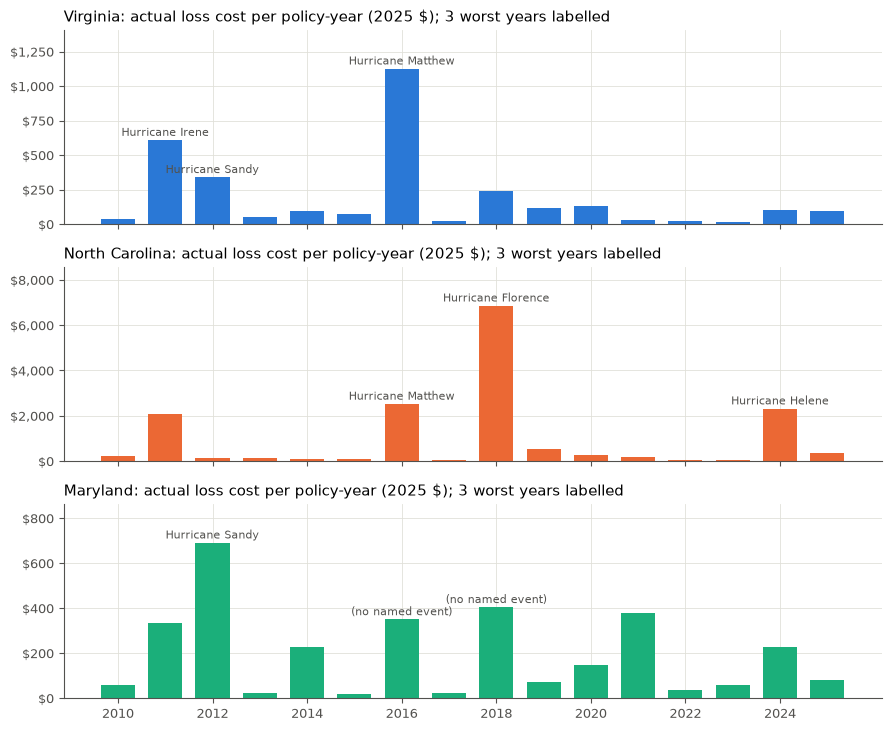

In [3]:
cells, claims = MS.load_data(verbose=False)
yr = cells.groupby(["state", "year"]).agg(exposure=("exposure", "sum"), claims=("claims", "sum"),
                                          losses=(MS.LOSS, "sum")).reset_index()
yr["loss_cost"] = yr["losses"] / yr["exposure"]
ev = r("transfer_by_year")[["state", "year", "top_event", "share_of_year_claims"]]
cat = MS.cat_years_by_state(cells)
fig, axes = plt.subplots(3, 1, figsize=(9, 7.4), sharex=True)
for ax, st in zip(axes, ["VA", "NC", "MD"]):
    d = yr[yr.state == st]
    ax.bar(d["year"], d["loss_cost"], color=COL[st], width=0.72)
    ax.set_title(f"{NAME[st]}: actual loss cost per policy-year (2025 $); 3 worst years labelled")
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:,.0f}"))
    top = d.nlargest(3, "losses")
    for _, row in top.iterrows():
        e = ev[(ev.state == st) & (ev.year == row.year)]["top_event"].iloc[0]
        if str(e).startswith("("):
            e = "(no named event)"
        ax.annotate(str(e)[:24], (row.year, row.loss_cost), xytext=(0, 3), textcoords="offset points",
                    ha="center", fontsize=8, color=INK2)
    ax.set_ylim(0, d["loss_cost"].max() * 1.25)
axes[-1].set_xticks(range(2010, 2026, 2))
fig.tight_layout(); save(fig, "11_loss_cost_by_state_year.png")
print("Cat years (top 3 by losses):", cat)

## 2. Transfer test: the Virginia model, unchanged, in NC and MD

"A/E" = actual losses / expected losses (1.0 = right on average).
- **North Carolina:** the Virginia model badly underestimates the **level**. A/E is **6.55** (frequency 3.95 x severity 1.64).
- **Maryland:** almost exactly right (A/E 0.99).

The by-year chart shows *where* NC's gap comes from:
- **storm years:** Florence 2018 at **46x** what the Virginia model expects, Matthew 2016 and Helene 2024 at about 16x, Irene 2011 at 13x;
- **quiet years:** NC is actually **below** the Virginia level (0.2x-0.8x).

So the gap is mostly hurricane exposure, not different buildings.

**What transferred well: the ranking.** The lift charts are as steep out of state as in Virginia. Scored within each state and year (so the level gap is taken out), the Virginia model's mean per-year improvement over a no-features model is:
- NC **12.6%**, MD **13.9%**;
- VA 15.0%, which is in-sample (the model was fitted on Virginia).

Gini is about 0.49-0.51 vs 0.53. The same building characteristics put buildings in the same order of risk in all three states.

**What didn't transfer, besides NC's level:** a few segments, shown in the segment chart.
- Maryland: contents-only policies (A/E 3.0), non-residential buildings (1.9) and non-tidal counties (2.1);
- North Carolina: buildings from 2000 or later (1.7) and primary residences (1.4).

In [4]:
tov = r("transfer_overall").set_index("state")
tov[["in_sample", "policy_years", "paid_claims", "actual_loss_cost", "expected_loss_cost", "ae_pure_premium",
     "ae_frequency", "ae_severity"]]

,in_sample,policy_years,paid_claims,actual_loss_cost,expected_loss_cost,ae_pure_premium,ae_frequency,ae_severity
state,,,,,,,,
VA,True,"1,482,412.768",9557,197.439,197.361,1.000,1.000,1.000
NC,False,"1,945,567.634",37825,988.413,150.889,6.551,3.952,1.643
MD,False,"674,956.727",4512,198.413,201.360,0.985,1.074,0.883


,state,year,claims,ae_frequency,ae_severity,ae_pure_premium,top_event,share_of_year_claims
16,NC,2010,1092,1.682,0.812,1.437,(no event name),1.000
17,NC,2011,7603,11.746,1.158,13.007,Hurricane Irene,0.979
18,NC,2012,777,1.194,0.751,0.939,Hurricane Sandy,0.781
19,NC,2013,391,0.600,0.976,0.761,(no event name),1.000
20,NC,2014,488,0.764,0.483,0.455,(no event name),0.909
21,NC,2015,481,0.776,0.818,0.690,October severe storms,0.604
22,NC,2016,5407,8.983,1.594,15.836,Hurricane Matthew,0.894
23,NC,2017,175,0.292,0.511,0.184,(no event name),1.000
24,NC,2018,13938,23.414,2.177,46.149,Hurricane Florence,0.938
25,NC,2019,1523,2.530,1.339,3.737,(no event name),1.000


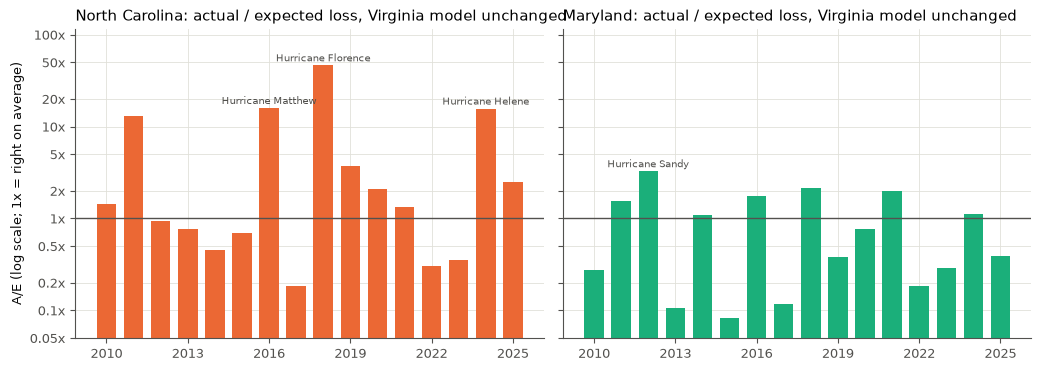

In [5]:
by = r("transfer_by_year")
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), sharey=True)
for ax, st in zip(axes, ["NC", "MD"]):
    d = by[by.state == st]
    ax.bar(d["year"], d["ae_pure_premium"], color=COL[st], width=0.72)
    ax.axhline(1, color=INK2, lw=1)
    ax.set_yscale("log"); ax.set_ylim(by[by.state != "VA"]["ae_pure_premium"].min() * 0.6, by[by.state != "VA"]["ae_pure_premium"].max() * 2.5); mult_axis(ax)
    ax.set_title(f"{NAME[st]}: actual / expected loss, Virginia model unchanged")
    for _, row in d.nlargest(3, MS.LOSS).iterrows():
        if str(row.top_event).startswith("("):          # no event name in the claims data
            continue
        ax.annotate(str(row.top_event)[:20], (row.year, row.ae_pure_premium), xytext=(0, 3),
                    textcoords="offset points", ha="center", fontsize=7.5, color=INK2)
    ax.set_xticks(range(2010, 2026, 3))
axes[0].set_ylabel("A/E (log scale; 1x = right on average)")
fig.tight_layout(); save(fig, "11_transfer_ae_by_year.png")
by[by.state != "VA"][["state", "year", "claims", "ae_frequency", "ae_severity", "ae_pure_premium", "top_event",
                      "share_of_year_claims"]]

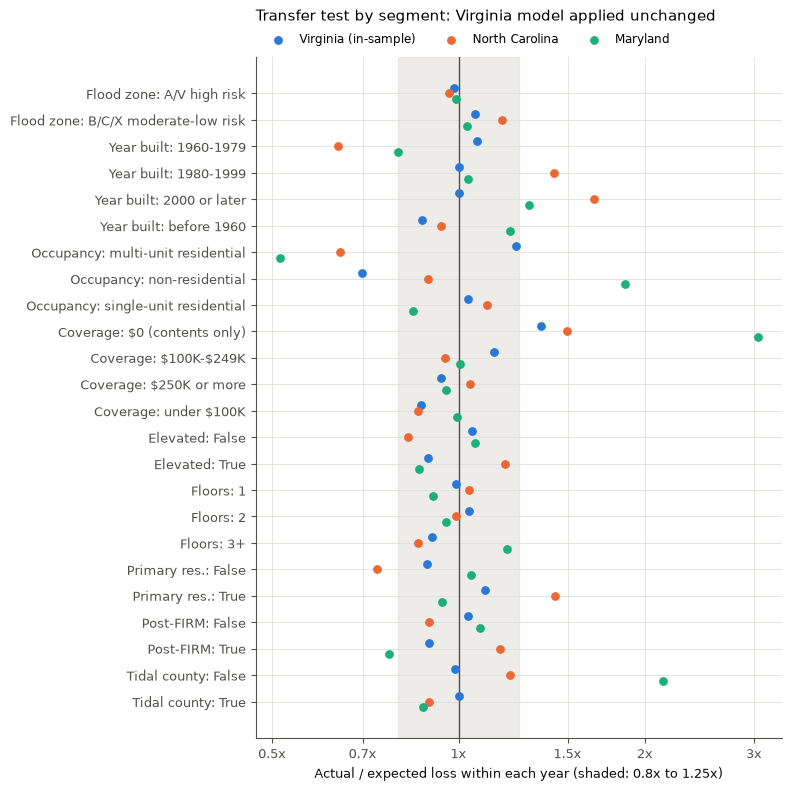

In [6]:
sg = r("transfer_segments")
s = sg[sg.kind == "pure_premium"].copy()
s["label"] = (s["feature"].map(LBL) + ": " + s["level"].astype(str)).map(esc)
order = s[s.state == "VA"]["label"].tolist()
fig, ax = plt.subplots(figsize=(8, 8))
y = np.arange(len(order))
for k, st in enumerate(["VA", "NC", "MD"]):
    d = s[s.state == st].set_index("label").reindex(order)
    ax.scatter(d["ae"], y + (k - 1) * 0.22, color=COL[st], s=28, label=NAME[st] + (" (in-sample)" if st == "VA" else ""), zorder=3)
ax.axvline(1, color=INK2, lw=1); ax.axvspan(0.8, 1.25, color=GRID, alpha=0.6, zorder=0)
ax.set_xscale("log"); mult_axis(ax, "x")
ax.set_yticks(y); ax.set_yticklabels(order); ax.invert_yaxis()
ax.set_xlabel("Actual / expected loss within each year (shaded: 0.8x to 1.25x)")
ax.set_title("Transfer test by segment: Virginia model applied unchanged", pad=26)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, frameon=False, fontsize=8.5)
fig.tight_layout(); save(fig, "11_transfer_segments.png")

,improvement_rebased_pct,gini
state,,
MD,13.928,0.510
NC,12.610,0.487
VA,15.049,0.530


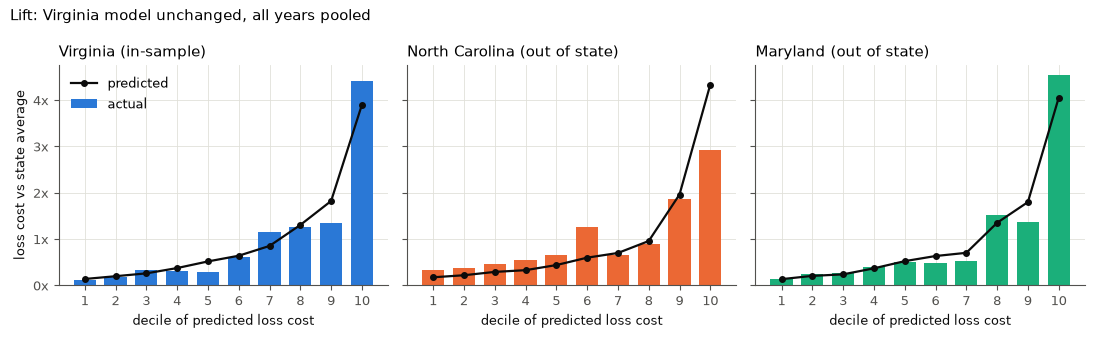

In [7]:
lf = r("transfer_lift")
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, st in zip(axes, ["VA", "NC", "MD"]):
    d = lf[lf.state == st]
    ax.bar(d["decile"], d["actual_relative"], color=COL[st], width=0.72, label="actual")
    ax.plot(d["decile"], d["pred_relative"], color=INK, marker="o", ms=4, lw=1.6, label="predicted")
    ax.set_title(NAME[st] + (" (in-sample)" if st == "VA" else " (out of state)"))
    ax.set_xticks(range(1, 11)); ax.set_xlabel("decile of predicted loss cost")
    mult_axis(ax)
axes[0].set_ylabel("loss cost vs state average"); axes[0].legend(frameon=False)
fig.suptitle("Lift: Virginia model unchanged, all years pooled", x=0.01, ha="left", fontsize=10.5)
fig.tight_layout(); save(fig, "11_transfer_lift.png")
ts = r("transfer_scores")
ts.groupby("state")[["improvement_rebased_pct", "gini"]].mean()

## 3. Refit on three states, with a state factor

Same structure as Virginia's production model (the same features and interactions), with two changes:
- **State x year effects:** each state gets its own effect for each year, because storms hit states in different years.
- **A state factor:** each state's average-year level vs Virginia, for the same mix of buildings.

State factors, including each state's off-balance:
- **North Carolina 6.22x** (frequency 3.51x, severity 1.73x);
- **Maryland 1.01x**.

The building relativities barely move from Virginia's (table below). The biggest change is buildings from 1960-1979, whose claim-frequency relativity is lower when all three states are pooled.

In [8]:
pm = production.load()
sf = pd.DataFrame(pm.card["state_factor_vs_virginia"]).T
print("State factors vs Virginia (average year, same building mix):"); display(sf)
rel = r("refit_relativities")
va = production.load(production.VA_PATH)
va_rel = MS.pp.combined_relativity_table(va.freq, va.sev).set_index(["feature", "level"])["pure_premium_rel"]
rel = rel.set_index(["feature", "level"])
rel["VA model (Milestone 11)"] = va_rel
rel[["frequency_rel", "severity_rel", "pure_premium_rel", "VA model (Milestone 11)"]]

State factors vs Virginia (average year, same building mix):


,frequency,severity,off_balance_ratio,pure_premium
VA,1.000,1.000,1.000,1.000
NC,3.506,1.728,1.026,6.216
MD,1.070,0.892,1.060,1.011


frequency_rel  severity_rel  pure_premium_rel  VA model (Milestone 11)
feature                level                                                                                          
flood_zone_group       A/V high risk                    1.000         1.000             1.000                    1.000
                       B/C/X moderate-low risk          0.450         0.758             0.341                    0.362
construction_band      1980-1999                        1.000         1.000             1.000                    1.000
                       before 1960                      1.800         1.154             2.078                    2.823
                       1960-1979                        1.664         1.201             1.998                    3.860
                       2000 or later                    0.664         1.027             0.682                    0.543
floors_group           2                                1.000         1.000             1.000                    1.000
                       1                                1.046         1.116             1.168                    1.007
                       3+                               0.993         0.899             0.892                    1.005
state                  VA                               1.000         1.000             1.000                      NaN
                       MD                               1.070         0.892             0.954                      NaN
                       NC                               3.506         1.728             6.059                      NaN
occupancy_group        single-unit residential          1.000         1.000             1.000                    1.000
                       non-residential                  1.000         4.280             4.280                    4.591
                       multi-unit residential           1.000         2.766             2.766                    2.839
building_coverage_band $250K or more                    1.000         1.000             1.000                    1.000
                       $0 (contents only)               1.000         0.477             0.477                    0.362
                       under $100K                      1.000         0.751             0.751                    0.792
                       $100K-$249K                      1.000         0.981             0.981                    0.914
primary_residence      True                             1.000         1.000             1.000                    1.000
                       False                            1.000         0.833             0.833                    1.070
elevated               False                            1.000         1.000             1.000                    1.000
                       True                             1.000         0.708             0.708                    0.719

## 4. Validation: unseen years, and an unseen state

**Leave-one-year-out (LOYO):** each of the 16 years is predicted by a model fitted on the other 15, and scored within each state. **Leave-one-state-out:** fit on two states and predict the third, the out-of-*state* version of the same idea.

Mean LOYO improvement, the production form (no county factor):
- VA 11.0%, NC 12.5%, MD 13.3%.

2021-2025 holdout:
- VA 9.5%, NC 16.7%, MD 16.6%.

Leave-one-state-out:
- **ranking:** improvement 10.9-13.2% in every state;
- **level:** wrong for the left-out state (it gets the base state's level). For example, NC predicted from VA+MD has raw A/E 6.3.

**Lesson:** the *relativities* travel between states; the *level* doesn't, so every state needs its own level. That is exactly what the state factor is.

In [9]:
summ = r("refit_summary")
sc = r("refit_scores")
tbl = summ.pivot(index="model", columns="state", values="mean_improvement").round(1)
tbl.columns = [f"{c} mean %" for c in tbl.columns]
gin = summ.pivot(index="model", columns="state", values="mean_gini").round(3)
gin.columns = [f"{c} Gini" for c in gin.columns]
ho = sc[sc.design == "holdout"].pivot(index="model", columns="state", values="improvement_rebased_pct").round(1)
ho.columns = [f"{c} holdout %" for c in ho.columns]
display(pd.concat([tbl, gin, ho], axis=1))
loso = sc[sc.design == "leave-one-state-out"].groupby("state")[["improvement_rebased_pct", "gini"]].mean()
print("Leave-one-state-out (fit on the other two states):"); display(loso)

,MD mean %,NC mean %,VA mean %,MD Gini,NC Gini,VA Gini,MD holdout %,NC holdout %,VA holdout %
model,,,,,,,,,
3-state GLM,13.300,12.500,11.000,0.497,0.477,0.455,16.600,16.700,9.500
3-state GLM + county,14.600,6.200,10.700,0.530,0.427,0.463,14.200,0.000,11.300
"VA model, unchanged",13.900,12.600,NaN,0.510,0.487,NaN,17.600,16.600,NaN
own-state GLM + county,14.100,6.300,11.000,0.541,0.417,0.479,12.400,2.100,10.300


Leave-one-state-out (fit on the other two states):


,improvement_rebased_pct,gini
state,,
MD,12.872,0.494
NC,13.165,0.493
VA,10.850,0.454


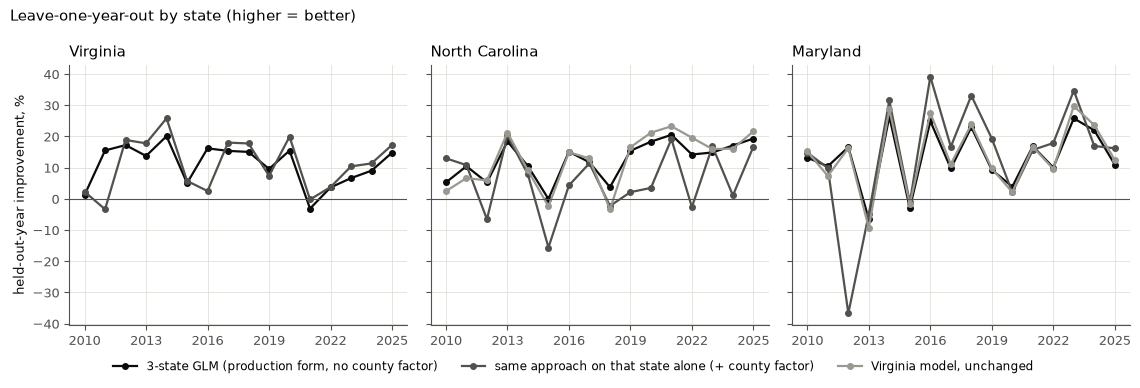

In [10]:
L = sc[sc.design == "LOYO"]
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.6), sharey=True)
show_models = [("3-state GLM", "3-state GLM (production form, no county factor)", INK),
               ("own-state GLM + county", "same approach on that state alone (+ county factor)", INK2),
               ("VA model, unchanged", "Virginia model, unchanged", "#9a9890")]
for ax, st in zip(axes, ["VA", "NC", "MD"]):
    for name, label, c in show_models:
        d = L[(L.state == st) & (L.model == name)].sort_values("test_year")
        ax.plot(d["test_year"], d["improvement_rebased_pct"], marker="o", ms=4, lw=1.6, color=c, label=label)
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_title(NAME[st]); ax.set_xticks(range(2010, 2026, 3))
axes[0].set_ylabel("held-out-year improvement, %")
h, l = axes[1].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=3, frameon=False, fontsize=8.5, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Leave-one-year-out by state (higher = better)", x=0.01, ha="left", fontsize=10.5)
fig.tight_layout(); save(fig, "11_loyo_by_state.png")

### The county factor: three forms tested (pre-stated rule)

The Milestone 11 county factor (Buhlmann-Straub on both frequency and severity) **made unseen years much worse in North Carolina**:
- LOYO 12.5% -> 6.2%;
- holdout 16.7% -> 0.04%.

The reason: a county's flood history in NC is mostly *one hurricane's footprint*. Florence flooded the Neuse and Cape Fear river counties; Helene hit the mountains. The next storm goes somewhere else, so a factor learnt from the last one points the wrong way.

The rule written before this test: use the form with the best average LOYO, unless its holdout falls below "no county factor" in more than one state.
- **Severity-only** has the best average, but only by 0.06 points, and it falls below "no county" on the holdout in NC and MD.
- So **production has no county factor**. Each county's estimate = its building mix x its state's level.

,LOYO MD,LOYO NC,LOYO VA,holdout MD,holdout NC,holdout VA,LOYO average of states,holdout states below no-county,chosen
model,,,,,,,,,
frequency + severity county factor,14.570,6.240,10.710,14.220,0.040,11.280,10.510,2,False
no county factor,13.340,12.510,10.970,16.570,16.700,9.520,12.270,0,True
severity-only county factor,13.430,11.190,12.370,16.460,14.780,11.800,12.330,2,False


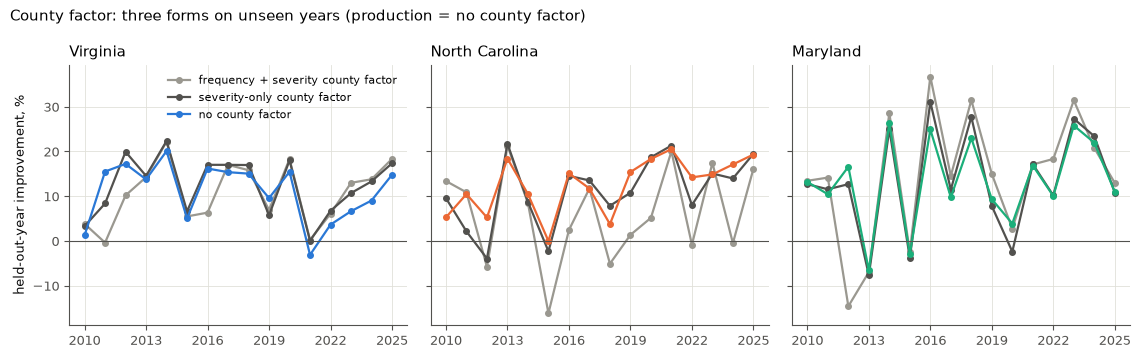

In [11]:
cf = r("county_form_summary").set_index("model")
display(cf.round(2))
L = r("county_form_scores"); L = L[L.design == "LOYO"]
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.6), sharey=True)
for ax, st in zip(axes, ["VA", "NC", "MD"]):
    for name, c in [("frequency + severity county factor", "#9a9890"), ("severity-only county factor", INK2),
                    ("no county factor", COL[st])]:
        d = L[(L.state == st) & (L.model == name)].sort_values("test_year")
        ax.plot(d["test_year"], d["improvement_rebased_pct"], marker="o", ms=4, lw=1.6, color=c, label=name)
    ax.axhline(0, color=INK2, lw=0.8); ax.set_title(NAME[st]); ax.set_xticks(range(2010, 2026, 3))
axes[0].set_ylabel("held-out-year improvement, %"); axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("County factor: three forms on unseen years (production = no county factor)", x=0.01, ha="left",
             fontsize=10.5)
fig.tight_layout(); save(fig, "11_county_form.png")

## 5. Are the relativities consistent across states?

The same model was fitted to each state alone (95% storm-aware confidence intervals in the charts). The rule was written in PROGRESS.md before any results were computed:
- **consistent:** same side of 1 everywhere, and the "same in all states" test is not rejected;
- **differs in size:** same direction, but the size differs;
- **inconsistent:** a state's confidence interval lies clearly on the other side.

The results:
- **Consistent:** flood zone (frequency), floors (severity).
- **Same direction, different size:** year built (frequency), occupancy, elevated, flood zone and elevated x zone (severity).
  - For example, 1960s-70s buildings claim 3.0x as often as 1980s-90s ones in Virginia, but 1.5x in North Carolina.
- **Inconsistent:** floors and year built x zone (frequency), year built (severity). These are small effects that flip sign between states.
- **Unclear:** coverage, coverage x occupancy, primary residence.
  - Second homes have smaller claims in NC (0.76x, plausibly Outer Banks beach houses) but not in VA or MD.

**Should the model use state-specific effects?** Seven "term x state" interactions passed the per-term keep rule. Put together, they were **worse in every state** on both the 16-year LOYO and the holdout, so none were adopted.

**Robustness:** using one shared year effect instead of state x year effects moves no relativity by more than 3.5%.

,kind,term,wald_p,label
0,frequency,construction_band,0.000,differs in size
1,frequency,construction_band x flood_zone_group,0.000,inconsistent
3,frequency,floors_group,0.065,inconsistent
2,frequency,flood_zone_group,0.224,consistent
12,severity,primary_residence,0.000,unclear
11,severity,occupancy_group,0.000,differs in size
5,severity,building_coverage_band x occupancy_group,0.000,unclear
7,severity,elevated,0.002,differs in size
4,severity,building_coverage_band,0.002,unclear
6,severity,construction_band,0.005,inconsistent


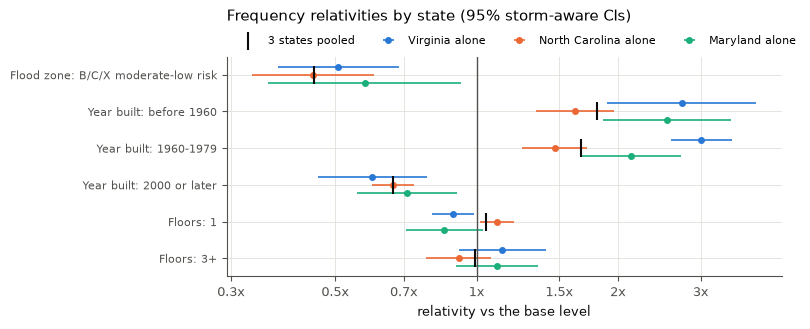

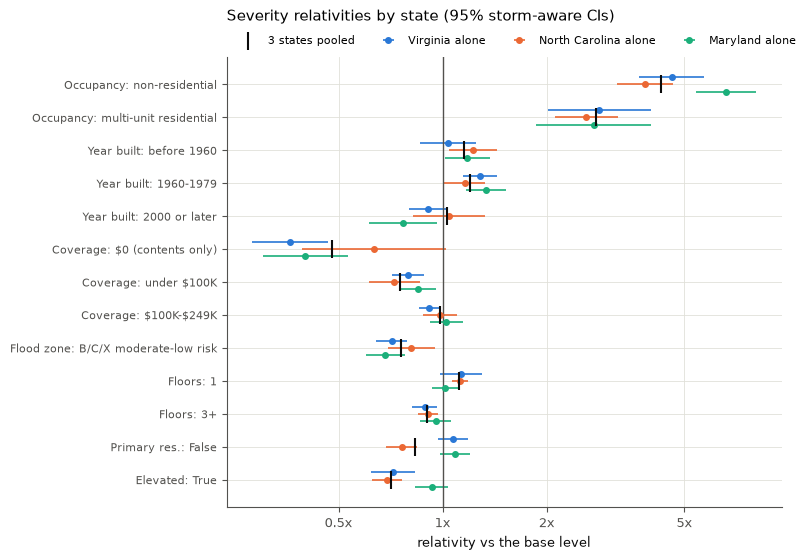

In [12]:
rs = r("relativities_by_state")
lab = r("consistency_labels"); het = r("heterogeneity_tests")
display(lab.sort_values(["kind", "wald_p"]))
def plot_rel(kind, fname):
    d = rs[(rs.kind == kind) & (~rs.term.str.contains(" x "))]
    cols = d[d.fit == "pooled"]["column"].tolist()
    fig, ax = plt.subplots(figsize=(8, 0.33 * len(cols) + 1.4))
    y = np.arange(len(cols))
    for k, fit in enumerate(["VA", "NC", "MD"]):
        g = d[d.fit == fit].set_index("column").reindex(cols)
        yy = y + (k - 1) * 0.22
        ax.errorbar(g["relativity"], yy, xerr=[g["relativity"] - g["ci_low"], g["ci_high"] - g["relativity"]],
                    fmt="o", ms=4, color=COL[fit], elinewidth=1.2, capsize=0, label=NAME[fit] + " alone")
    p = d[d.fit == "pooled"].set_index("column").reindex(cols)
    ax.scatter(p["relativity"], y, marker="|", s=160, color=INK, label="3 states pooled", zorder=4)
    ax.axvline(1, color=INK2, lw=1); ax.set_xscale("log"); mult_axis(ax, "x")
    ax.set_yticks(y); ax.set_yticklabels([nice_col(c) for c in cols], fontsize=8); ax.invert_yaxis()
    ax.set_title(f"{kind.capitalize()} relativities by state (95% storm-aware CIs)", pad=26)
    ax.set_xlabel("relativity vs the base level")
    ax.legend(frameon=False, fontsize=8, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=4)
    fig.tight_layout(); save(fig, fname)
plot_rel("frequency", "11_relativities_frequency.png")
plot_rel("severity", "11_relativities_severity.png")

In [13]:
kp = REP / "10_state_interaction_keep_rule.csv"
display(pd.read_csv(kp) if kp.exists() else "no term had a significant state difference")
display(r("shared_year_sensitivity").assign(change=lambda d: d["ratio"] - 1).sort_values("change", key=abs, ascending=False).head(10))

,kind,term,dev_loyo_base,dev_loyo_with_state_interaction,gain_points,state_years_better,state_years,passes_loyo
0,frequency,construction_band,5.694,6.095,0.401,21,33,True
1,frequency,construction_band x flood_zone_group,5.694,7.087,1.393,17,33,True
2,severity,building_coverage_band,17.335,17.315,-0.020,13,33,False
3,severity,building_coverage_band x occupancy_group,17.335,17.437,0.102,18,33,True
4,severity,construction_band,17.335,17.314,-0.021,18,33,False
5,severity,elevated,17.335,17.622,0.287,17,33,True
6,severity,elevated x flood_zone_group,17.335,17.405,0.069,17,33,True
7,severity,flood_zone_group,17.335,17.501,0.166,23,33,True
8,severity,occupancy_group,17.335,17.218,-0.118,18,33,False
9,severity,primary_residence,17.335,18.633,1.298,21,33,True


,kind,column,state_x_year,shared_year,ratio,change
16,severity,building_coverage_band[$0 (contents only)],0.477,0.494,1.035,0.035
29,severity,building_coverage_band[$100K-$249K]:occupancy_...,0.653,0.635,0.974,-0.026
21,severity,floors_group[3+],0.899,0.880,0.979,-0.021
28,severity,building_coverage_band[$100K-$249K]:occupancy_...,0.417,0.408,0.980,-0.020
26,severity,building_coverage_band[under $100K]:occupancy_...,0.304,0.298,0.980,-0.020
24,severity,building_coverage_band[$0 (contents only)]:occ...,1.121,1.101,0.983,-0.017
22,severity,primary_residence[False],0.833,0.821,0.986,-0.014
12,severity,occupancy_group[multi-unit residential],2.766,2.805,1.014,0.014
23,severity,elevated[True],0.708,0.700,0.988,-0.012
15,severity,construction_band[2000 or later],1.027,1.035,1.007,0.007


## 6. Credibility: what more data changed

Buhlmann-Straub's k (= process noise / true differences between counties) says how many claims a county needs before its own history gets 50% weight:
- **Virginia alone:** frequency differences between counties were pure storm noise (k = infinity, Z = 0); severity k = 33 claims.
- **Pooled three states:** frequency k = 160 (no longer infinite), severity k = 41; the median county's severity Z is 0.41.

More counties made the *estimated* county differences look real for frequency. But the out-of-sample test (section 4) showed they don't repeat, so credibility alone isn't enough: the factor must also *predict*.

The second chart shows why the app labels certainty carefully. Without a county factor, many big counties' 2010-2025 history differs from the model:
- coastal resort counties are lower: Brunswick 0.35x, New Hanover 0.28x, Worcester 0.39x;
- river counties hit by one storm are higher: Craven 3.6x.

Only about 16% of exposure sits in counties within 0.8-1.25x.

,fit,part,epv,vhm,k,counties,median_Z
0,VA alone,freq,17.408,-0.038,inf,134,0.000
1,VA alone,sev,2.102,0.064,33.104,134,0.249
2,NC alone,freq,72.840,0.316,230.384,101,0.250
3,NC alone,sev,7.156,0.126,56.589,101,0.546
4,MD alone,freq,30.846,0.368,83.786,25,0.493
5,MD alone,sev,2.503,0.049,50.567,25,0.635
6,3 states pooled,freq,40.087,0.250,160.299,260,0.175
7,3 states pooled,sev,4.615,0.111,41.391,260,0.408


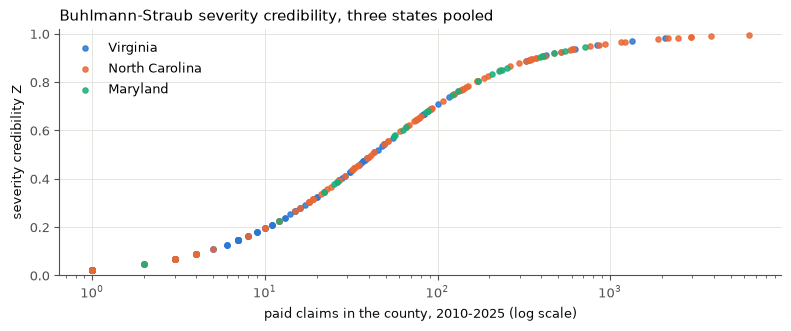

In [14]:
cr = r("credibility")
display(cr)
ct = pd.read_csv(ROOT / "data" / "processed" / "m13_county_table.csv", dtype={"county": str})
ct["state"] = ct["county"].map(E.state_of)
fig, ax = plt.subplots(figsize=(8, 3.4))
for st in ["VA", "NC", "MD"]:
    d = ct[(ct.state == st) & (ct.s_n > 0)]
    ax.scatter(d["s_n"], d["Z_sev"], s=14, color=COL[st], label=NAME[st], alpha=0.85)
ax.set_xscale("log"); ax.set_xlabel("paid claims in the county, 2010-2025 (log scale)")
ax.set_ylabel("severity credibility Z"); ax.set_ylim(0, 1.02)
ax.set_title("Buhlmann-Straub severity credibility, three states pooled")
ax.legend(frameon=False)
fig.tight_layout(); save(fig, "11_credibility_z.png")

share of exposure (30+ claim counties) within 0.8-1.25: 0.153


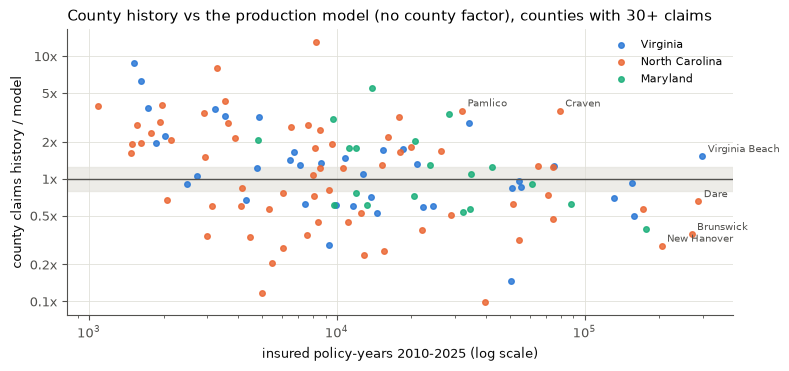

In [15]:
cs = pd.read_csv(ROOT / "app" / "data" / "county_summary.csv", dtype={"county": str})
cs = cs[cs.paid_claims_2010_2025 >= 30]
fig, ax = plt.subplots(figsize=(8, 3.8))
for st in ["VA", "NC", "MD"]:
    d = cs[cs.state == st]
    ax.scatter(d["policy_years_2010_2025"], d["history_vs_model"], s=16, color=COL[st], label=NAME[st], alpha=0.85)
ax.axhspan(0.8, 1.25, color=GRID, alpha=0.6, zorder=0); ax.axhline(1, color=INK2, lw=1)
ax.set_xscale("log"); ax.set_yscale("log"); mult_axis(ax)
ax.set_xlabel("insured policy-years 2010-2025 (log scale)")
ax.set_ylabel("county claims history / model")
ax.set_title("County history vs the production model (no county factor), counties with 30+ claims")
lab = pd.concat([cs.nlargest(4, "policy_years_2010_2025"),
                 cs[(cs.history_vs_model > 2.5) | (cs.history_vs_model < 0.3)].nlargest(3, "paid_claims_2010_2025")])
for _, row in lab.drop_duplicates("county").iterrows():
    ax.annotate(row["name"].replace(" County", "").replace(" city", ""),
                (row.policy_years_2010_2025, row.history_vs_model),
                xytext=(4, 3), textcoords="offset points", fontsize=7.5, color=INK2)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); save(fig, "11_county_history_vs_model.png")
w = cs.policy_years_2010_2025
print("share of exposure (30+ claim counties) within 0.8-1.25:",
      round(float(w[cs.history_vs_model.between(0.8, 1.25)].sum() / w.sum()), 3))

## 7. XGBoost check (frozen Milestone 10 settings, refitted once per fold)

XGBoost is more accurate on average:
- the XGBoost **Tweedie** beats the GLM's LOYO by **+3.8 points** pooled (bootstrap CI 1.6 to 5.5);
- it is better on every state's holdout.

But the Milestone 11 rule needs **all six** criteria, and neither challenger passes them all:
- **XGB Tweedie** fails:
  - criterion 3: catastrophe years in VA (13.2 vs 16.3) and MD (15.4 vs 21.5);
  - criterion 5: it under-predicts segments the GLM gets right (moderate/low-risk zones 0.67-0.79, coverage under $100K 0.61-0.71);
  - criterion 1 in MD (CI includes 0).
  - Its monotone constraints *do* fix the explainability flips (criterion 6 passes).
- **XGB frequency x severity** fails criteria 1 (NC, MD), 3 (VA), 5 and 6 (elevation raises its predicted frequency for 96-98% of exposure).

**The Milestone 11 recommendation holds: the GLM stays in production.**

In [16]:
xs = r("xgb_scores")
xsum = r("xgb_summary")
display(xsum.pivot(index="model", columns="state", values="mean_improvement").round(2))
display(xsum.pivot(index="model", columns="state", values="mean_gini").round(3))
display(xs[xs.design == "holdout"].pivot(index="model", columns="state", values="improvement_rebased_pct").round(2))
o = pd.read_parquet(ROOT / "data" / "processed" / "m13_oof_xgb.parquet")
models = ["3-state hybrid GLM (production)", "XGB freq x sev", "XGB Tweedie"]
rows = []
for st in ["VA", "NC", "MD"]:
    d = o[o.state == st]
    for m in models:
        rows.append({"state": st, "model": m, "raw_ae": d[MS.LOSS].sum() / d[m].sum()})
display(pd.DataFrame(rows).pivot(index="model", columns="state", values="raw_ae").round(3))

state,MD,NC,VA
model,,,
3-state hybrid GLM (production),13.340,12.510,10.970
XGB Tweedie,16.730,14.680,16.750
XGB freq x sev,14.020,13.480,13.760


state,MD,NC,VA
model,,,
3-state hybrid GLM (production),0.497,0.477,0.455
XGB Tweedie,0.588,0.529,0.579
XGB freq x sev,0.504,0.495,0.509


state,MD,NC,VA
model,,,
3-state hybrid GLM (production),16.570,16.700,9.520
XGB Tweedie,18.430,16.810,14.710
XGB freq x sev,17.310,18.900,12.330


state,MD,NC,VA
model,,,
3-state hybrid GLM (production),0.988,0.988,0.989
XGB Tweedie,0.985,0.984,0.987
XGB freq x sev,0.986,0.985,0.988


In [17]:
seg = []
for st in ["VA", "NC", "MD", "all"]:
    d = o if st == "all" else o[o.state == st]
    for m in models:
        rb = MS.rebase_by(d[m], d[MS.LOSS], d["state"] + d["year"].astype(str))
        t = MS.segment_ae(d, d[MS.LOSS].to_numpy(), rb, ["flood_zone_group", "elevated", "building_coverage_band",
                                                          "occupancy_group", "construction_band"])
        seg.append(t.assign(state=st, model=m))
seg = pd.concat(seg)
out_band = seg[(seg.ae < 0.8) | (seg.ae > 1.25)]
display(out_band.pivot_table(index=["state", "feature", "level"], columns="model", values="ae").round(2))
display(r("xgb_flip_check").pivot_table(index=["kind", "flip"], columns="state", values="share_exposure_wrong_way").round(3))

model                                                 3-state hybrid GLM (production)  XGB Tweedie  XGB freq x sev
state feature                level                                                                                
MD    building_coverage_band $0 (contents only)                                 2.370        1.950           1.680
                             under $100K                                          NaN        0.710             NaN
      construction_band      1980-1999                                          0.760          NaN           0.740
                             2000 or later                                        NaN          NaN           0.760
      elevated               True                                                 NaN          NaN           0.720
      flood_zone_group       B/C/X moderate-low risk                              NaN        0.670             NaN
      occupancy_group        multi-unit residential                             0.620          NaN           0.640
                             non-residential                                    2.200        1.900           1.700
                             single-unit residential                            0.760        0.720             NaN
NC    building_coverage_band under $100K                                          NaN        0.700             NaN
      flood_zone_group       B/C/X moderate-low risk                              NaN        0.750             NaN
      occupancy_group        multi-unit residential                             0.730          NaN             NaN
VA    building_coverage_band $0 (contents only)                                   NaN        0.710           0.770
                             under $100K                                          NaN        0.610             NaN
      construction_band      1960-1979                                          1.340        1.350           1.340
                             1980-1999                                          0.720        0.780           0.690
                             2000 or later                                      0.650        0.620           0.560
                             before 1960                                        0.800        0.770             NaN
      elevated               True                                                 NaN          NaN           0.750
      flood_zone_group       B/C/X moderate-low risk                              NaN        0.790             NaN
      occupancy_group        multi-unit residential                             1.450        1.630           1.590
                             non-residential                                      NaN        0.680           0.660
all   building_coverage_band under $100K                                          NaN        0.690             NaN
      flood_zone_group       B/C/X moderate-low risk                              NaN        0.750             NaN

state                                                           MD    NC    VA
kind      flip                                                                
frequency elevated: False -> True                            0.958 0.975 0.969
          flood_zone_group: A/V high risk -> B/C/X modera... 0.013 0.009 0.006
severity  building_coverage_band: $100K-$249K -> $250K or... 0.134 0.210 0.102
          elevated: False -> True                            0.445 0.055 0.138
          flood_zone_group: A/V high risk -> B/C/X modera... 0.227 0.369 0.122
tweedie   building_coverage_band: $100K-$249K -> $250K or... 0.000 0.000 0.000
          elevated: False -> True                            0.000 0.000 0.000
          flood_zone_group: A/V high risk -> B/C/X modera... 0.000 0.000 0.000

In [18]:
dec = r("xgb_decision")
show = dec[["challenger", "state"] + [c for c in dec.columns if c.endswith("pass")] + ["passes all"]]
display(show)
display(dec[["challenger", "state", "1 LOYO diff (pts)", "1 CI low", "1 CI high", "3 cat-year GLM", "3 cat-year XGB",
             "5 segments newly outside 0.8-1.25", "6 worst wrong-way flip"]].round(2))

,challenger,state,1 pass,2 pass,3 pass,4 pass,5 pass,6 pass,passes all
0,XGB freq x sev,VA,True,True,False,True,False,False,False
1,XGB freq x sev,NC,False,True,True,True,True,False,False
2,XGB freq x sev,MD,False,True,True,True,False,False,False
3,XGB freq x sev,pooled,True,True,True,True,False,False,False
4,XGB Tweedie,VA,True,True,False,True,False,True,False
5,XGB Tweedie,NC,True,True,True,True,False,True,False
6,XGB Tweedie,MD,False,True,False,True,False,True,False
7,XGB Tweedie,pooled,True,True,False,True,False,True,False


,challenger,state,1 LOYO diff (pts),1 CI low,1 CI high,3 cat-year GLM,3 cat-year XGB,5 segments newly outside 0.8-1.25,6 worst wrong-way flip
0,XGB freq x sev,VA,2.790,1.040,4.330,16.300,14.800,elevated=True (0.75); building_coverage_band=$...,frequency elevated: False -> True: 97%
1,XGB freq x sev,NC,0.970,-1.170,3.150,11.980,17.610,NaN,frequency elevated: False -> True: 98%
2,XGB freq x sev,MD,0.680,-0.640,1.950,21.480,25.350,elevated=True (0.72); construction_band=2000 o...,frequency elevated: False -> True: 96%
3,XGB freq x sev,pooled,1.480,0.410,2.500,16.590,19.250,county_group=24029 (0.73); county_group=51001 ...,frequency elevated: False -> True: 98%
4,XGB Tweedie,VA,5.790,2.880,8.350,16.300,13.170,flood_zone_group=B/C/X moderate-low risk (0.79...,tweedie elevated: False -> True: 0%
5,XGB Tweedie,NC,2.170,0.740,3.620,11.980,13.160,flood_zone_group=B/C/X moderate-low risk (0.75...,tweedie elevated: False -> True: 0%
6,XGB Tweedie,MD,3.390,-2.240,7.000,21.480,15.360,flood_zone_group=B/C/X moderate-low risk (0.67...,tweedie elevated: False -> True: 0%
7,XGB Tweedie,pooled,3.780,1.580,5.540,16.590,13.890,flood_zone_group=B/C/X moderate-low risk (0.75...,tweedie elevated: False -> True: 0%


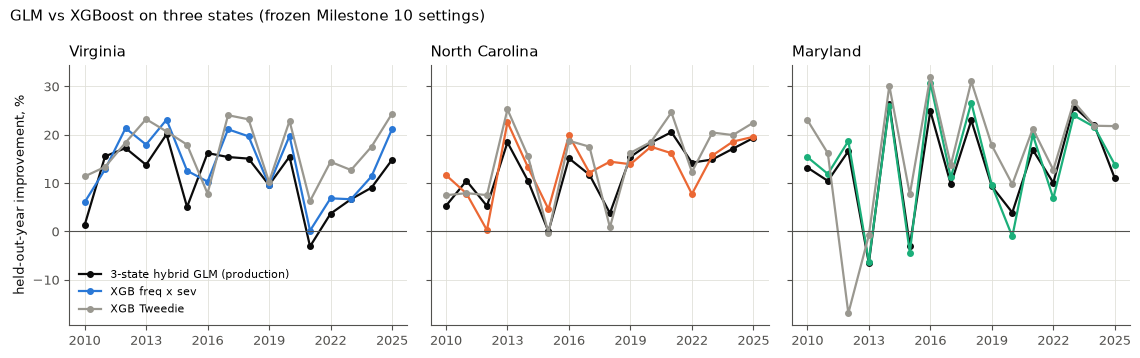

In [19]:
L = xs[xs.design == "LOYO"]
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.6), sharey=True)
for ax, st in zip(axes, ["VA", "NC", "MD"]):
    for name, c in [("3-state hybrid GLM (production)", INK), ("XGB freq x sev", COL[st]), ("XGB Tweedie", "#9a9890")]:
        d = L[(L.state == st) & (L.model == name)].sort_values("test_year")
        ax.plot(d["test_year"], d["improvement_rebased_pct"], marker="o", ms=4, lw=1.6, color=c, label=name)
    ax.axhline(0, color=INK2, lw=0.8); ax.set_title(NAME[st]); ax.set_xticks(range(2010, 2026, 3))
axes[0].set_ylabel("held-out-year improvement, %"); axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("GLM vs XGBoost on three states (frozen Milestone 10 settings)", x=0.01, ha="left", fontsize=10.5)
fig.tight_layout(); save(fig, "11_xgb_vs_glm.png")

## 8. App data: every county in the three states

`app/data/` covers **257 counties/cities** (VA 133, NC 100, MD 24). Each county is compared with **its own state's** average:
- VA $197, NC $988, MD $198 per policy-year (average year, 2025 dollars).

The certainty label combines two things:
- how much local claim history there is (Z);
- whether that history agrees with the model.

Two example counties follow, each with its sentence, uncertainty note and waterfall.

In [20]:
ex = E.load()
cs = ex.county_summary
print(cs.groupby("state").size().rename("counties/cities"))
for st in ["VA", "NC", "MD"]:
    print(f"{NAME[st]} average ${ex.averages['states'][st]['expected_pure_premium_per_policy_year']:,.2f} per policy-year")
cols = ["state", "name", "policy_years_2010_2025", "paid_claims_2010_2025", "expected_pure_premium", "ratio_to_state",
        "history_vs_model", "certainty"]
display(cs[cs.policy_years_2010_2025 > 20000].sort_values("expected_pure_premium", ascending=False)[cols].head(12))

state
MD     24
NC    100
VA    133
Name: counties/cities, dtype: int64
Virginia average $197.33 per policy-year
North Carolina average $987.85 per policy-year
Maryland average $198.30 per policy-year


,state,name,policy_years_2010_2025,paid_claims_2010_2025,expected_pure_premium,ratio_to_state,history_vs_model,certainty
59,NC,Beaufort County,"64,597.300",2955,"1,258.340",1.274,1.267,Medium
65,NC,Durham County,"22,087.800",195,"1,214.640",1.230,0.384,Low
72,NC,Pitt County,"28,795.500",353,"1,140.620",1.155,0.504,Medium
73,NC,Pasquotank County,"39,796.400",140,"1,138.860",1.153,0.098,Low
74,NC,Mecklenburg County,"51,245.800",606,"1,131.230",1.145,0.626,Medium
79,NC,Craven County,"79,310.800",3853,"1,050.340",1.063,3.587,Low
80,NC,Carteret County,"171,309.000",2949,"1,032.080",1.045,0.571,Medium
83,NC,New Hanover County,"204,302.000",1896,974.369,0.986,0.283,Low
87,NC,Pamlico County,"31,999.900",2481,946.426,0.958,3.596,Low
90,NC,Dare County,"287,370.000",6349,915.346,0.927,0.654,Medium


Model-based expected flood losses for insured buildings in Dare County, NC are close to the North Carolina average (about $915 vs $988 per policy-year in an average year); no single factor moves it much. This is an area-level estimate, not a prediction for any individual property.
Medium certainty. This estimate comes from the county's mix of insured buildings and its state's level; the county's own claim history is not used to adjust it, because county adjustments made unseen years less accurate (in North Carolina a county's history is mostly one hurricane's footprint). There is plenty of local claim history to check it against (6,349 paid claims, credibility Z = 0.99); over 2010-2025 this county's claims cost about 0.7x what the model expects, so the true level here may differ from the estimate. Such county differences did not repeat reliably in unseen years, so the model doesn't follow them.



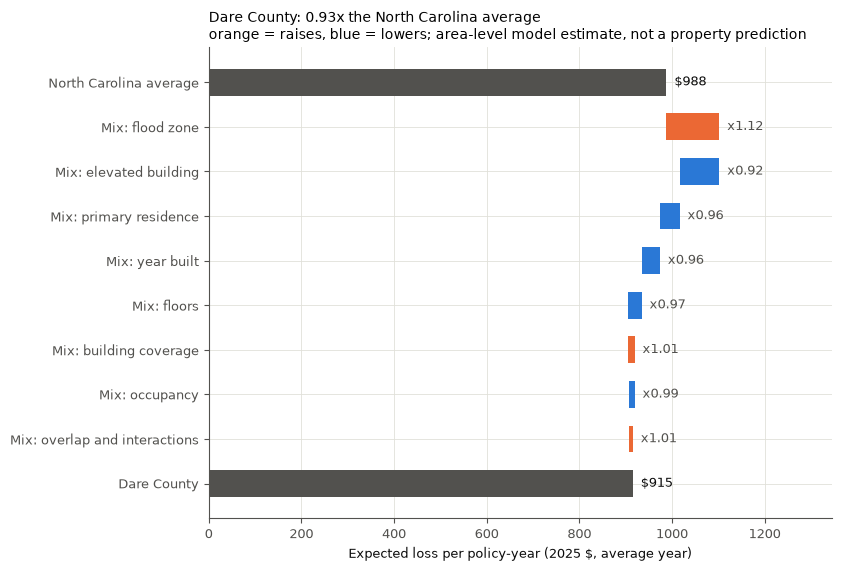

Model-based expected flood losses for insured buildings in Worcester County, MD are close to the Maryland average (about $198 vs $198 per policy-year in an average year): pushing it up, 29% of insured buildings here are multi-unit or non-residential buildings (Maryland: 15%); pulling it down, 33% of insured buildings here were built before 1980 (Maryland: 46%). This is an area-level estimate, not a prediction for any individual property.
Low certainty. This estimate comes from the county's mix of insured buildings and its state's level; the county's own claim history is not used to adjust it, because county adjustments made unseen years less accurate (in North Carolina a county's history is mostly one hurricane's footprint). There is plenty of local claim history to check it against (548 paid claims, credibility Z = 0.93); over 2010-2025 this county's claims cost about 0.4x what the model expects, so the true level here may differ from the estimate. Such county differences did not repe

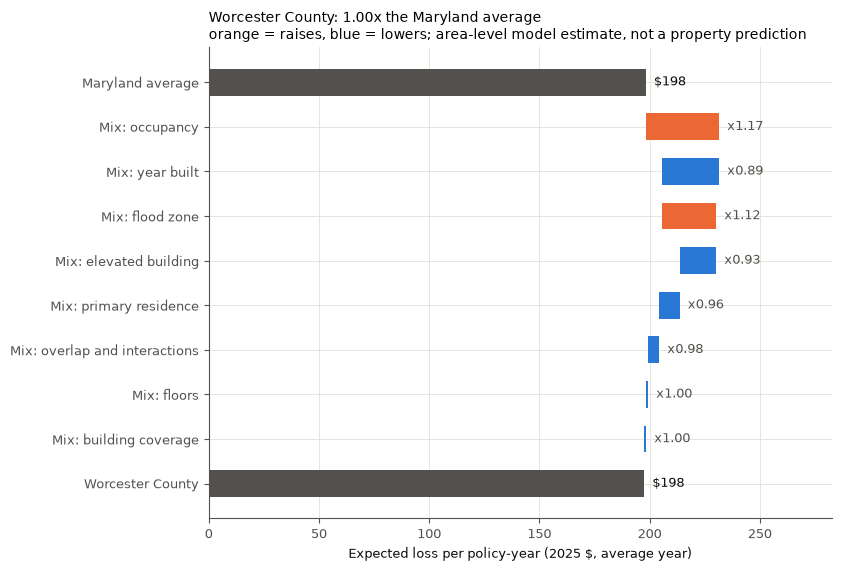

In [21]:
for name in ["Dare County, NC", "Worcester County, MD"]:
    e = ex.explain_county(name)
    print(e["sentence"]); print(e["uncertainty_note"]); print()
    fig = E.plot_waterfall(e); save(fig, f"11_waterfall_{e['county']}.png"); plt.show()

## 9. Limitations
- **Three neighbouring Atlantic states.** The state factor is an average-year level estimated from 16 years. NC's is dominated by four hurricanes, so it is uncertain (a different 16 years would give a different number).
- **No geography inside a state** beyond the building mix, so county estimates can be far from county history. The certainty label says so.
- **Tidal definitions differ by state** (each state's own law), so "tidal" isn't exactly the same thing in each.
- **NFIP buyers aren't random.** Everything describes the insured population.
- **Area level only.** None of this is a prediction for an individual property.